# Homework 4

## Setup

### Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    KFold
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

from sklearn.svm import SVC, SVR
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

### Mount Google Drive

In [ ]:
drive.mount('/content/Drive')

cancer_path = (
    '/content/Drive/MyDrive/Colab Notebooks/Cancer.csv'
)

housing_path = (
    '/content/Drive/MyDrive/Colab Notebooks/Housing.csv'
)

SEED = 42

MessageError: Error: credential propagation was unsuccessful

### Helper Functions

#### Machine Learning Pipeline

In [ ]:
def make_pipeline(model):
    return Pipeline([
        (
            'imputer',
            SimpleImputer(strategy='median')
        ),
        (
            'scaler',
            StandardScaler()
        ),
        (
            'model',
            model
        )
    ])

#### Grid Search Function

In [ ]:
def tune_model(
    estimator,
    parameter_grid,
    X_train,
    y_train,
    cv,
    scoring
):
    search = GridSearchCV(
        estimator=estimator,
        param_grid=parameter_grid,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    search.fit(
        X_train,
        y_train
    )

    return search

#### Normalization Function

In [ ]:
def normalize_inputs(
    X_train,
    X_test
):
    minimum = np.min(
        X_train,
        axis=0
    )

    maximum = np.max(
        X_train,
        axis=0
    )

    feature_range = (
        maximum - minimum
    )

    feature_range = np.where(
        feature_range == 0,
        1,
        feature_range
    )

    X_train_normalized = (
        (X_train - minimum)
        / feature_range
    )

    X_test_normalized = (
        (X_test - minimum)
        / feature_range
    )

    return (
        X_train_normalized,
        X_test_normalized
    )

#### Regularized Linear Regression Function

In [ ]:
def gradient_descent_l2(
    X_train,
    y_train,
    X_test,
    y_test,
    learning_rate,
    iterations,
    lambda_reg
):
    m = len(y_train)

    theta = np.zeros(
        X_train.shape[1]
    )

    train_cost_history = []
    test_cost_history = []

    for i in range(iterations):

        predictions = (
            X_train @ theta
        )

        errors = (
            predictions - y_train
        )

        regularization = (
            theta.copy()
        )

        regularization[0] = 0

        gradient = (
            (X_train.T @ errors) / m
            + (lambda_reg / m)
            * regularization
        )

        theta -= (
            learning_rate * gradient
        )

        train_predictions = (
            X_train @ theta
        )

        train_errors = (
            train_predictions
            - y_train
        )

        test_predictions = (
            X_test @ theta
        )

        test_errors = (
            test_predictions
            - y_test
        )

        train_cost = (
            np.sum(
                train_errors ** 2
            )
            / (2 * m)
            + (
                lambda_reg
                / (2 * m)
            )
            * np.sum(
                theta[1:] ** 2
            )
        )

        test_cost = (
            np.sum(
                test_errors ** 2
            )
            / (
                2
                * len(y_test)
            )
        )

        train_cost_history.append(
            train_cost
        )

        test_cost_history.append(
            test_cost
        )

    return (
        theta,
        train_cost_history,
        test_cost_history
    )

## Problem 1

### Load Cancer Dataset

In [ ]:
cancer = pd.read_csv(
    cancer_path
)

print(
    "# of samples:",
    len(cancer)
)

print(
    "Columns:"
)

print(
    list(cancer.columns)
)

# of samples: 569
Columns:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


### Inspect Cancer Dataset

In [ ]:
print(
    "\nDataset shape:",
    cancer.shape
)

print(
    "\nClass distribution:"
)

print(
    cancer[
        'diagnosis'
    ].value_counts()
)

print(
    "\nMissing values:"
)

print(
    cancer.isnull().sum()
)


Dataset shape: (569, 33)

Class distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Missing values:
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_wors

### Clean Cancer Dataset

In [ ]:
diagnosis = (
    cancer['diagnosis']
    .astype(str)
    .str.strip()
    .str.upper()
)

y_cancer = diagnosis.map({
    'B': 0,
    'M': 1
})

drop_columns = [
    'diagnosis'
]

for column in cancer.columns:

    if (
        column == 'id'
        or column.startswith(
            'Unnamed:'
        )
    ):
        drop_columns.append(
            column
        )

X_cancer = cancer.drop(
    columns=drop_columns
)

X_cancer = (
    X_cancer
    .apply(
        pd.to_numeric,
        errors='raise'
    )
)

### Select I/O Variables

In [ ]:
X = X_cancer
y = y_cancer

print(
    "\nInput shape:",
    X.shape
)

print(
    "Output shape:",
    y.shape
)

print(
    "\nTarget labels:"
)

print(
    "0 = Benign"
)

print(
    "1 = Malignant"
)


Input shape: (569, 30)
Output shape: (569,)

Target labels:
0 = Benign
1 = Malignant


### 80/20 Test Split

In [ ]:
X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=SEED,
        stratify=y
    )
)

print(
    "\nTraining samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

print(
    "\nTraining class distribution:"
)

print(
    y_train.value_counts()
)

print(
    "\nTest class distribution:"
)

print(
    y_test.value_counts()
)


Training samples: 455
Testing samples: 114

Training class distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Test class distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


### SVM Cross Validation

In [ ]:
cancer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

### SVM Kernel Settings

In [ ]:
svc_settings = {

    'Linear': {
        'kernel': 'linear',
        'parameters': {
            'model__C': [
                0.1,
                1,
                10
            ]
        }
    },

    'RBF': {
        'kernel': 'rbf',
        'parameters': {
            'model__C': [
                0.1,
                1,
                10
            ],
            'model__gamma': [
                'scale',
                0.01,
                0.1
            ]
        }
    },

    'Polynomial': {
        'kernel': 'poly',
        'parameters': {
            'model__C': [
                0.1,
                1,
                10
            ],
            'model__degree': [
                2,
                3
            ],
            'model__gamma': [
                'scale'
            ],
            'model__coef0': [
                0,
                1
            ]
        }
    },

    'Sigmoid': {
        'kernel': 'sigmoid',
        'parameters': {
            'model__C': [
                0.1,
                1,
                10
            ],
            'model__gamma': [
                'scale',
                0.001,
                0.01
            ],
            'model__coef0': [
                0,
                1
            ]
        }
    }
}

### Train SVM Models

In [ ]:
svm_searches = {}

for kernel_name, settings in (
    svc_settings.items()
):

    print(
        "Training",
        kernel_name,
        "SVM..."
    )

    model = make_pipeline(
        SVC(
            kernel=settings[
                'kernel'
            ]
        )
    )

    search = tune_model(
        estimator=model,
        parameter_grid=settings[
            'parameters'
        ],
        X_train=X_train,
        y_train=y_train,
        cv=cancer_cv,
        scoring='accuracy'
    )

    svm_searches[
        kernel_name
    ] = search

Training Linear SVM...
Training RBF SVM...
Training Polynomial SVM...
Training Sigmoid SVM...


### SVM Classification Results

In [ ]:
svm_results = []

svm_predictions = {}

for kernel_name, search in (
    svm_searches.items()
):

    prediction = search.predict(
        X_test
    )

    svm_predictions[
        kernel_name
    ] = prediction

    accuracy = accuracy_score(
        y_test,
        prediction
    )

    precision = precision_score(
        y_test,
        prediction,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        prediction,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        prediction,
        zero_division=0
    )

    svm_results.append({
        'Kernel': kernel_name,
        'CV Accuracy': search.best_score_,
        'Test Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })


svm_results_df = (
    pd.DataFrame(
        svm_results
    )
    .set_index(
        'Kernel'
    )
)

print(
    "\nSVM Classification Results"
)

print(
    "--------------------------"
)

print(
    svm_results_df.round(4)
)


SVM Classification Results
--------------------------
            CV Accuracy  Test Accuracy  Precision  Recall  F1 Score
Kernel                                                             
Linear           0.9670         0.9825     1.0000  0.9524    0.9756
RBF              0.9758         0.9737     1.0000  0.9286    0.9630
Polynomial       0.9824         0.9825     1.0000  0.9524    0.9756
Sigmoid          0.9648         0.9474     0.9737  0.8810    0.9250


### Best SVM Parameters

In [ ]:
for kernel_name, search in (
    svm_searches.items()
):

    print(
        kernel_name,
        ":",
        search.best_params_
    )

Linear : {'model__C': 0.1}
RBF : {'model__C': 10, 'model__gamma': 'scale'}
Polynomial : {'model__C': 1, 'model__coef0': 1, 'model__degree': 3, 'model__gamma': 'scale'}
Sigmoid : {'model__C': 1, 'model__coef0': 0, 'model__gamma': 'scale'}


### Classification Accuracy, Precision, and Recall

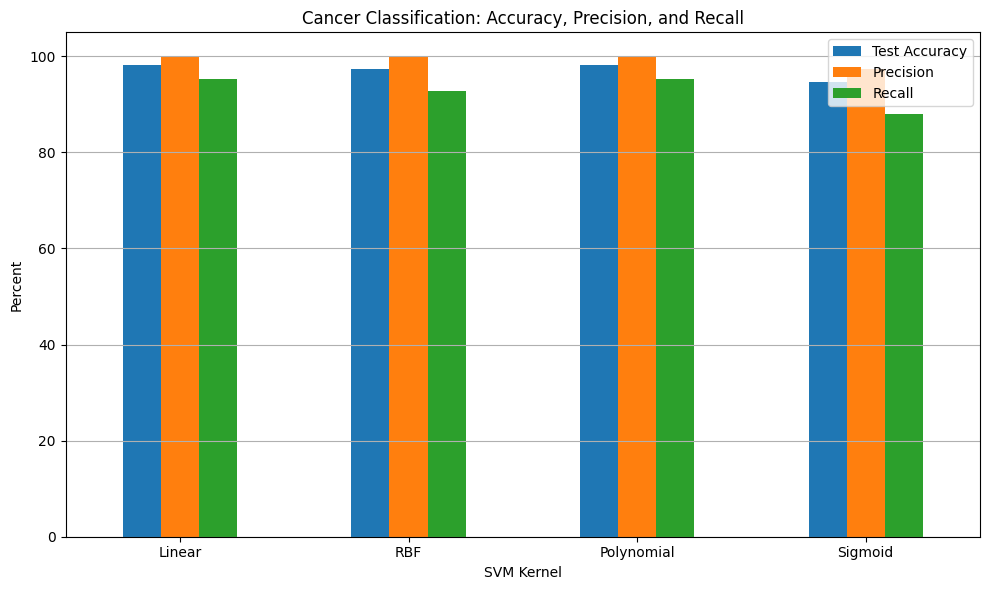

In [ ]:
plot_data = (
    svm_results_df[
        [
            'Test Accuracy',
            'Precision',
            'Recall'
        ]
    ]
    * 100
)

plot_data.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.xlabel(
    'SVM Kernel'
)

plt.ylabel(
    'Percent'
)

plt.title(
    'Cancer Classification: '
    'Accuracy, Precision, and Recall'
)

plt.ylim(
    0,
    105
)

plt.xticks(
    rotation=0
)

plt.grid(
    True,
    axis='y'
)

plt.tight_layout()

plt.show()

### SVM Kernel Accuracy Comparison

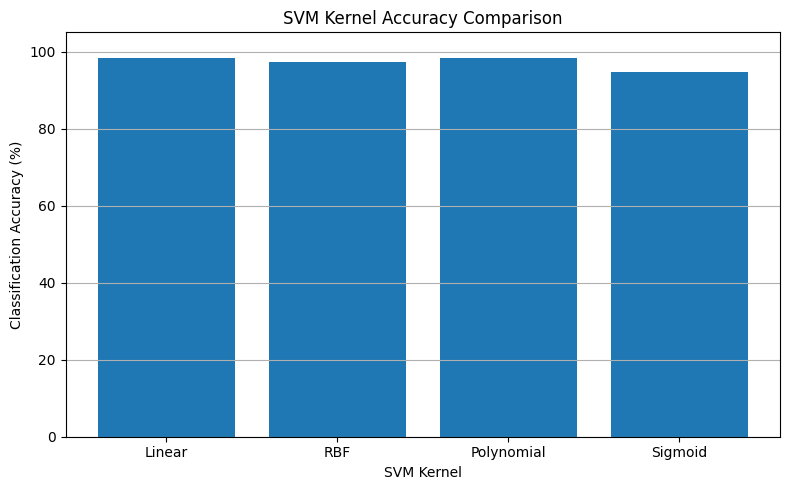

In [ ]:
plt.figure(
    figsize=(8, 5)
)

plt.bar(
    svm_results_df.index,
    svm_results_df[
        'Test Accuracy'
    ] * 100
)

plt.xlabel(
    'SVM Kernel'
)

plt.ylabel(
    'Classification Accuracy (%)'
)

plt.title(
    'SVM Kernel Accuracy Comparison'
)

plt.ylim(
    0,
    105
)

plt.grid(
    True,
    axis='y'
)

plt.tight_layout()

plt.show()

### Logistic Regression Comparison with Homework 3

#### Prepare Cancer Data

In [ ]:
cancer_imputer = SimpleImputer(
    strategy='median'
)

X_train_imputed = (
    cancer_imputer
    .fit_transform(
        X_train
    )
)

X_test_imputed = (
    cancer_imputer
    .transform(
        X_test
    )
)

cancer_scaler = (
    StandardScaler()
)

X_train_scaled = (
    cancer_scaler
    .fit_transform(
        X_train_imputed
    )
)

X_test_scaled = (
    cancer_scaler
    .transform(
        X_test_imputed
    )
)

#### Homework 3 Logistic Regression

In [ ]:
iterations = 500

classes = np.array([
    0,
    1
])

logistic_model = (
    SGDClassifier(
        loss='log_loss',
        penalty=None,
        learning_rate='constant',
        eta0=0.001,
        random_state=42
    )
)

for i in range(
    iterations
):
    logistic_model.partial_fit(
        X_train_scaled,
        y_train,
        classes=classes
    )

#### Homework 3 L2 Logistic Regression

In [ ]:
logistic_l2_model = (
    SGDClassifier(
        loss='log_loss',
        penalty='l2',
        alpha=0.01,
        learning_rate='constant',
        eta0=0.001,
        random_state=42
    )
)

for i in range(
    iterations
):
    logistic_l2_model.partial_fit(
        X_train_scaled,
        y_train,
        classes=classes
    )

#### Logistic Regression Results

In [ ]:
logistic_predictions = (
    logistic_model.predict(
        X_test_scaled
    )
)

logistic_l2_predictions = (
    logistic_l2_model.predict(
        X_test_scaled
    )
)

logistic_results = []

for name, prediction in [

    (
        'Logistic Regression',
        logistic_predictions
    ),

    (
        'Logistic Regression + L2',
        logistic_l2_predictions
    )

]:

    logistic_results.append({

        'Model': name,

        'Test Accuracy':
            accuracy_score(
                y_test,
                prediction
            ),

        'Precision':
            precision_score(
                y_test,
                prediction,
                zero_division=0
            ),

        'Recall':
            recall_score(
                y_test,
                prediction,
                zero_division=0
            ),

        'F1 Score':
            f1_score(
                y_test,
                prediction,
                zero_division=0
            )
    })


logistic_results_df = (
    pd.DataFrame(
        logistic_results
    )
    .set_index(
        'Model'
    )
)

print(
    logistic_results_df.round(4)
)

                          Test Accuracy  Precision  Recall  F1 Score
Model                                                               
Logistic Regression              0.9737     0.9756  0.9524    0.9639
Logistic Regression + L2         0.9825     1.0000  0.9524    0.9756


#### SVM vs Logistic Regression

In [ ]:
comparison_rows = []

for kernel_name in (
    svm_results_df.index
):

    comparison_rows.append({

        'Model':
            'SVM ' + kernel_name,

        'Accuracy':
            svm_results_df.loc[
                kernel_name,
                'Test Accuracy'
            ],

        'Precision':
            svm_results_df.loc[
                kernel_name,
                'Precision'
            ],

        'Recall':
            svm_results_df.loc[
                kernel_name,
                'Recall'
            ]
    })


for model_name in (
    logistic_results_df.index
):

    comparison_rows.append({

        'Model':
            model_name,

        'Accuracy':
            logistic_results_df.loc[
                model_name,
                'Test Accuracy'
            ],

        'Precision':
            logistic_results_df.loc[
                model_name,
                'Precision'
            ],

        'Recall':
            logistic_results_df.loc[
                model_name,
                'Recall'
            ]
    })


classification_comparison_df = (
    pd.DataFrame(
        comparison_rows
    )
    .set_index(
        'Model'
    )
)

classification_comparison_df.round(4)

,Accuracy,Precision,Recall
Model,,,
SVM Linear,0.9825,1.0000,0.9524
SVM RBF,0.9737,1.0000,0.9286
SVM Polynomial,0.9825,1.0000,0.9524
SVM Sigmoid,0.9474,0.9737,0.8810
Logistic Regression,0.9737,0.9756,0.9524
Logistic Regression + L2,0.9825,1.0000,0.9524


### SVM vs Logistic Regression Plot

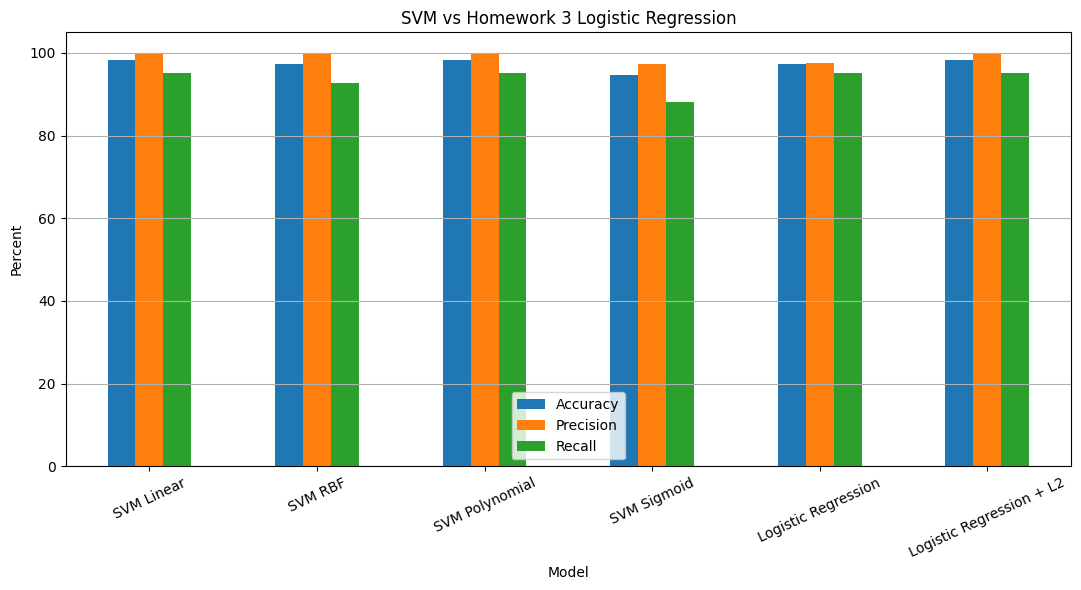

In [ ]:
(
    classification_comparison_df
    * 100
).plot(
    kind='bar',
    figsize=(11, 6)
)

plt.xlabel(
    'Model'
)

plt.ylabel(
    'Percent'
)

plt.title(
    'SVM vs Homework 3 '
    'Logistic Regression'
)

plt.ylim(
    0,
    105
)

plt.xticks(
    rotation=25
)

plt.grid(
    True,
    axis='y'
)

plt.tight_layout()

plt.show()

### Select Best SVM Kernel

In [ ]:
best_svm_kernel = max(
    svm_searches,
    key=lambda name:
        svm_searches[
            name
        ].best_score_
)

best_svm_prediction = (
    svm_predictions[
        best_svm_kernel
    ]
)

print(
    "Best SVM Kernel:",
    best_svm_kernel
)

print(
    "Test Accuracy:",
    round(
        accuracy_score(
            y_test,
            best_svm_prediction
        ),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(
            y_test,
            best_svm_prediction
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_test,
            best_svm_prediction
        ),
        4
    )
)

Best SVM Kernel: Polynomial
Test Accuracy: 0.9825
Precision: 1.0
Recall: 0.9524


### Best SVM Confusion Matrix

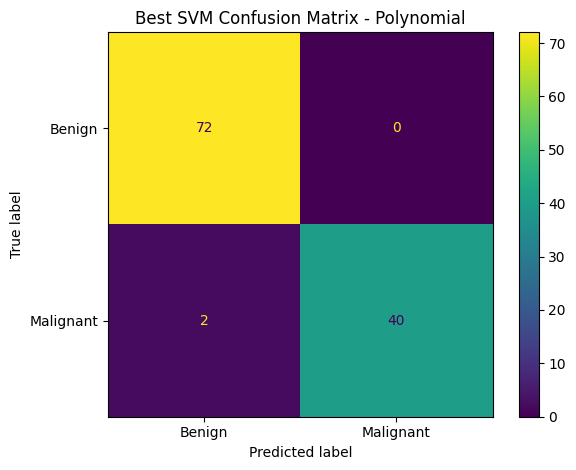

In [ ]:
best_svm_cm = (
    confusion_matrix(
        y_test,
        best_svm_prediction
    )
)

best_svm_display = (
    ConfusionMatrixDisplay(
        confusion_matrix=
            best_svm_cm,

        display_labels=[
            'Benign',
            'Malignant'
        ]
    )
)

best_svm_display.plot()

plt.title(
    'Best SVM Confusion Matrix - '
    + best_svm_kernel
)

plt.tight_layout()

plt.show()

## Problem 2

### Load Housing Dataset

In [ ]:
housing = pd.read_csv(
    housing_path
)

print(
    "# of samples:",
    len(housing)
)

print(
    "Columns:"
)

print(
    list(housing.columns)
)

# of samples: 545
Columns:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


### Inspect Housing Dataset

In [ ]:
print(
    "\nDataset shape:",
    housing.shape
)

print(
    "\nMissing values:"
)

print(
    housing.isnull().sum()
)


Dataset shape: (545, 13)

Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


### Encode Binary Input Variables

In [ ]:
binary_features = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea'
]

housing_encoded = (
    housing.copy()
)

for feature in (
    binary_features
):

    housing_encoded[
        feature
    ] = (
        housing_encoded[
            feature
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            'yes': 1,
            'no': 0
        })
    )

### Select I/O Variables

In [ ]:
housing_features = [
    'area',
    'bedrooms',
    'bathrooms',
    'stories',
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'parking',
    'prefarea'
]

X_housing = (
    housing_encoded[
        housing_features
    ]
    .to_numpy(
        dtype=float
    )
)

y_housing = (
    housing_encoded[
        'price'
    ]
    .to_numpy(
        dtype=float
    )
)

print(
    "Input matrix shape:",
    X_housing.shape
)

print(
    "Output vector shape:",
    y_housing.shape
)

Input matrix shape: (545, 11)
Output vector shape: (545,)


### 80/20 Training/Test Split

In [ ]:
np.random.seed(
    8675309
)

indices = (
    np.random.permutation(
        len(X_housing)
    )
)

split_index = int(
    len(X_housing)
    * 0.80
)

train_indices = (
    indices[
        :split_index
    ]
)

test_indices = (
    indices[
        split_index:
    ]
)

X_housing_train = (
    X_housing[
        train_indices
    ]
)

X_housing_test = (
    X_housing[
        test_indices
    ]
)

y_housing_train = (
    y_housing[
        train_indices
    ]
)

y_housing_test = (
    y_housing[
        test_indices
    ]
)

print(
    "Training samples:",
    len(
        X_housing_train
    )
)

print(
    "Testing samples:",
    len(
        X_housing_test
    )
)

Training samples: 436
Testing samples: 109


### SVR Cross Validation

In [ ]:
housing_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

### SVR Kernel Settings

In [ ]:
svr_settings = {

    'Linear': {
        'kernel': 'linear',

        'parameters': {
            'regressor__model__C': [
                0.1,
                1,
                10
            ],

            'regressor__model__epsilon': [
                0.05,
                0.1,
                0.2
            ]
        }
    },

    'RBF': {
        'kernel': 'rbf',

        'parameters': {
            'regressor__model__C': [
                0.1,
                1,
                10
            ],

            'regressor__model__gamma': [
                'scale',
                0.01,
                0.1
            ],

            'regressor__model__epsilon': [
                0.05,
                0.1,
                0.2
            ]
        }
    },

    'Polynomial': {
        'kernel': 'poly',

        'parameters': {
            'regressor__model__C': [
                0.1,
                1,
                10
            ],

            'regressor__model__degree': [
                2,
                3
            ],

            'regressor__model__gamma': [
                'scale'
            ],

            'regressor__model__coef0': [
                0,
                1
            ],

            'regressor__model__epsilon': [
                0.05,
                0.1,
                0.2
            ]
        }
    },

    'Sigmoid': {
        'kernel': 'sigmoid',

        'parameters': {
            'regressor__model__C': [
                0.1,
                1,
                10
            ],

            'regressor__model__gamma': [
                'scale',
                0.001,
                0.01
            ],

            'regressor__model__coef0': [
                0,
                1
            ],

            'regressor__model__epsilon': [
                0.05,
                0.1,
                0.2
            ]
        }
    }
}

### Train SVR Models

In [ ]:
svr_searches = {}

for kernel_name, settings in (
    svr_settings.items()
):

    print(
        "Training",
        kernel_name,
        "SVR..."
    )

    svr_pipeline = (
        make_pipeline(
            SVR(
                kernel=settings[
                    'kernel'
                ]
            )
        )
    )

    model = (
        TransformedTargetRegressor(
            regressor=
                svr_pipeline,

            transformer=
                StandardScaler()
        )
    )

    search = tune_model(
        estimator=model,
        parameter_grid=settings[
            'parameters'
        ],
        X_train=
            X_housing_train,
        y_train=
            y_housing_train,
        cv=housing_cv,
        scoring=
            'neg_root_mean_squared_error'
    )

    svr_searches[
        kernel_name
    ] = search

Training Linear SVR...
Training RBF SVR...
Training Polynomial SVR...
Training Sigmoid SVR...


### SVR Regression Results

In [ ]:
svr_results = []

svr_predictions = {}

for kernel_name, search in (
    svr_searches.items()
):

    prediction = search.predict(
        X_housing_test
    )

    train_prediction = (
        search.predict(
            X_housing_train
        )
    )

    svr_predictions[
        kernel_name
    ] = prediction

    rmse = np.sqrt(
        mean_squared_error(
            y_housing_test,
            prediction
        )
    )

    mae = (
        mean_absolute_error(
            y_housing_test,
            prediction
        )
    )

    r2 = r2_score(
        y_housing_test,
        prediction
    )

    train_r2 = r2_score(
        y_housing_train,
        train_prediction
    )

    svr_results.append({

        'Kernel':
            kernel_name,

        'CV RMSE':
            -search.best_score_,

        'Test RMSE':
            rmse,

        'Test MAE':
            mae,

        'Test R2':
            r2,

        'Train R2':
            train_r2
    })


svr_results_df = (
    pd.DataFrame(
        svr_results
    )
    .set_index(
        'Kernel'
    )
)

print(
    svr_results_df.round(4)
)

                 CV RMSE    Test RMSE     Test MAE  Test R2  Train R2
Kernel                                                               
Linear      1.146742e+06  868581.3262  652532.4883   0.7540    0.6459
RBF         1.148357e+06  857726.2368  659266.2140   0.7601    0.7096
Polynomial  1.143663e+06  865513.1841  649926.4501   0.7557    0.6944
Sigmoid     1.157100e+06  866018.3918  650236.3806   0.7554    0.6288


### Best SVR Parameters

In [ ]:
for kernel_name, search in (
    svr_searches.items()
):

    print(
        kernel_name,
        ":",
        search.best_params_
    )

Linear : {'regressor__model__C': 0.1, 'regressor__model__epsilon': 0.2}
RBF : {'regressor__model__C': 10, 'regressor__model__epsilon': 0.2, 'regressor__model__gamma': 0.01}
Polynomial : {'regressor__model__C': 0.1, 'regressor__model__coef0': 1, 'regressor__model__degree': 2, 'regressor__model__epsilon': 0.2, 'regressor__model__gamma': 'scale'}
Sigmoid : {'regressor__model__C': 10, 'regressor__model__coef0': 0, 'regressor__model__epsilon': 0.2, 'regressor__model__gamma': 0.01}


### SVR RMSE Comparison

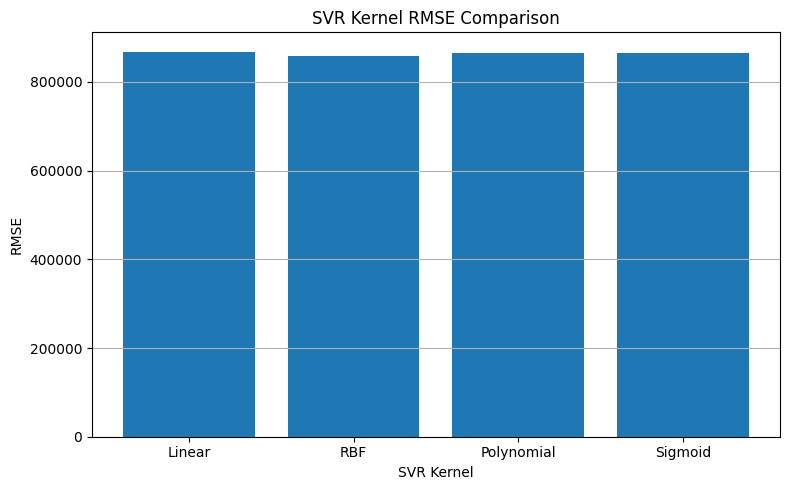

In [ ]:
plt.figure(
    figsize=(8, 5)
)

plt.bar(
    svr_results_df.index,
    svr_results_df[
        'Test RMSE'
    ]
)

plt.xlabel(
    'SVR Kernel'
)

plt.ylabel(
    'RMSE'
)

plt.title(
    'SVR Kernel RMSE Comparison'
)

plt.grid(
    True,
    axis='y'
)

plt.tight_layout()

plt.show()

### SVR R² Comparison

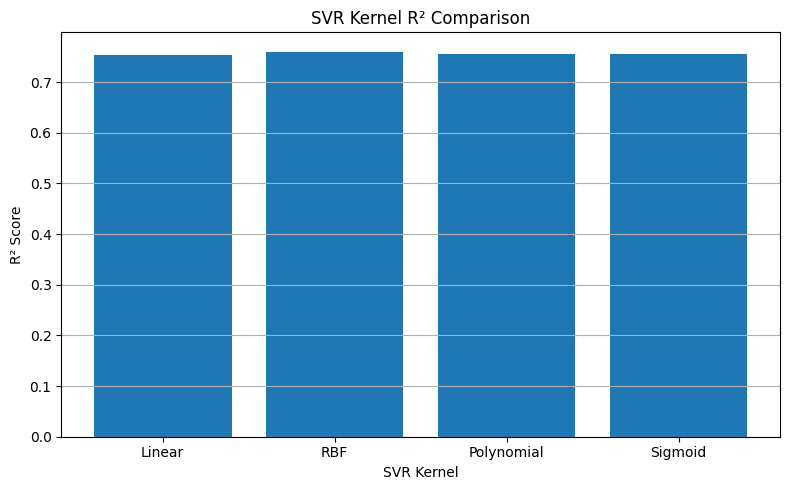

In [ ]:
plt.figure(
    figsize=(8, 5)
)

plt.bar(
    svr_results_df.index,
    svr_results_df[
        'Test R2'
    ]
)

plt.xlabel(
    'SVR Kernel'
)

plt.ylabel(
    'R² Score'
)

plt.title(
    'SVR Kernel R² Comparison'
)

plt.grid(
    True,
    axis='y'
)

plt.tight_layout()

plt.show()

### Actual vs Predicted Housing Prices

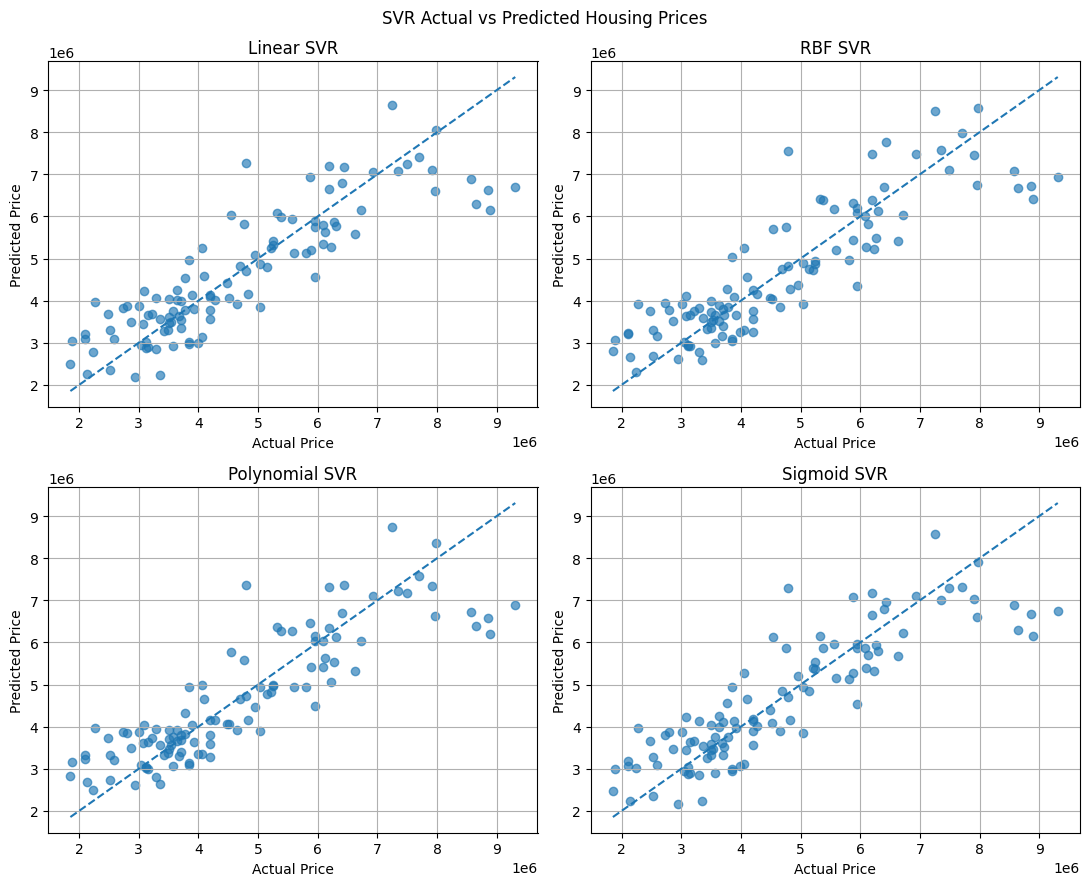

In [ ]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 9)
)

for ax, kernel_name in zip(
    axes.flat,
    svr_predictions
):

    prediction = (
        svr_predictions[
            kernel_name
        ]
    )

    ax.scatter(
        y_housing_test,
        prediction,
        alpha=0.65
    )

    minimum_value = min(
        y_housing_test.min(),
        prediction.min()
    )

    maximum_value = max(
        y_housing_test.max(),
        prediction.max()
    )

    ax.plot(
        [
            minimum_value,
            maximum_value
        ],
        [
            minimum_value,
            maximum_value
        ],
        '--'
    )

    ax.set_xlabel(
        'Actual Price'
    )

    ax.set_ylabel(
        'Predicted Price'
    )

    ax.set_title(
        kernel_name
        + ' SVR'
    )

    ax.grid(
        True
    )

plt.suptitle(
    'SVR Actual vs Predicted Housing Prices'
)

plt.tight_layout()

plt.show()

### SVR Regression Curves

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(


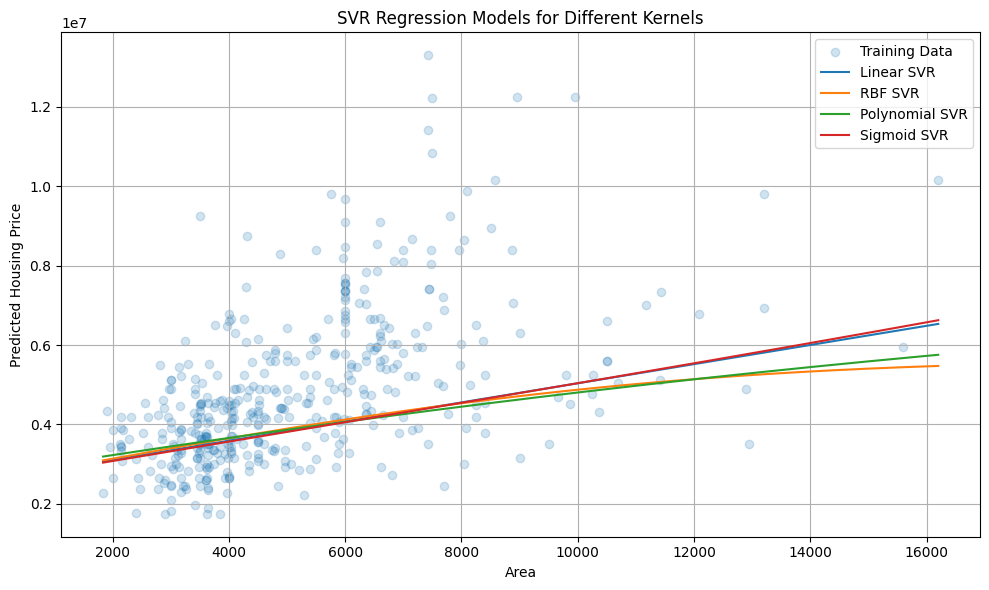

In [ ]:
training_df = pd.DataFrame(
    X_housing_train,
    columns=housing_features
)

area_values = np.linspace(
    training_df[
        'area'
    ].min(),

    training_df[
        'area'
    ].max(),

    200
)

typical_house = (
    training_df.median()
)

for feature in (
    binary_features
):

    typical_house[
        feature
    ] = (
        training_df[
            feature
        ]
        .mode()
        .iloc[0]
    )

curve_data = pd.DataFrame(
    [
        typical_house.to_dict()
        for i in range(
            len(area_values)
        )
    ]
)

curve_data[
    'area'
] = area_values

plt.figure(
    figsize=(10, 6)
)

plt.scatter(
    training_df[
        'area'
    ],
    y_housing_train,
    alpha=0.20,
    label='Training Data'
)

for kernel_name, search in (
    svr_searches.items()
):

    curve_prediction = (
        search.predict(
            curve_data[
                housing_features
            ]
        )
    )

    plt.plot(
        area_values,
        curve_prediction,
        label=
            kernel_name
            + ' SVR'
    )

plt.xlabel(
    'Area'
)

plt.ylabel(
    'Predicted Housing Price'
)

plt.title(
    'SVR Regression Models for Different Kernels'
)

plt.legend()

plt.grid(
    True
)

plt.tight_layout()

plt.show()

### Regularized Linear Regression Comparison

#### Normalize Input Data

In [ ]:
(
    X_previous_train,
    X_previous_test
) = normalize_inputs(
    X_housing_train,
    X_housing_test
)

#### Add Bias Term

In [ ]:
X_previous_train_bias = (
    np.column_stack((
        np.ones(
            len(
                X_previous_train
            )
        ),
        X_previous_train
    ))
)

X_previous_test_bias = (
    np.column_stack((
        np.ones(
            len(
                X_previous_test
            )
        ),
        X_previous_test
    ))
)

#### Regularization Settings

In [ ]:
previous_learning_rate = 0.10

previous_iterations = 1000

lambda_reg = 0.10

#### Train Regularized Linear Regression

In [ ]:
(
    previous_theta,
    previous_train_cost,
    previous_test_cost
) = gradient_descent_l2(

    X_previous_train_bias,

    y_housing_train,

    X_previous_test_bias,

    y_housing_test,

    learning_rate=
        previous_learning_rate,

    iterations=
        previous_iterations,

    lambda_reg=
        lambda_reg
)

#### Regularized Linear Regression Predictions

In [ ]:
previous_train_prediction = (
    X_previous_train_bias
    @ previous_theta
)

previous_test_prediction = (
    X_previous_test_bias
    @ previous_theta
)

#### Regularized Linear Regression Results

In [ ]:
previous_rmse = np.sqrt(
    mean_squared_error(
        y_housing_test,
        previous_test_prediction
    )
)

previous_mae = (
    mean_absolute_error(
        y_housing_test,
        previous_test_prediction
    )
)

previous_r2 = (
    r2_score(
        y_housing_test,
        previous_test_prediction
    )
)

previous_train_r2 = (
    r2_score(
        y_housing_train,
        previous_train_prediction
    )
)

print(
    "Learning Rate:",
    previous_learning_rate
)

print(
    "Iterations:",
    previous_iterations
)

print(
    "Lambda:",
    lambda_reg
)

print(
    "Test RMSE:",
    round(
        previous_rmse,
        4
    )
)

print(
    "Test MAE:",
    round(
        previous_mae,
        4
    )
)

print(
    "Test R²:",
    round(
        previous_r2,
        4
    )
)

Learning Rate: 0.1
Iterations: 1000
Lambda: 0.1
Test RMSE: 873050.7773
Test MAE: 663554.3867
Test R²: 0.7514


#### Regularized Linear Regression Loss

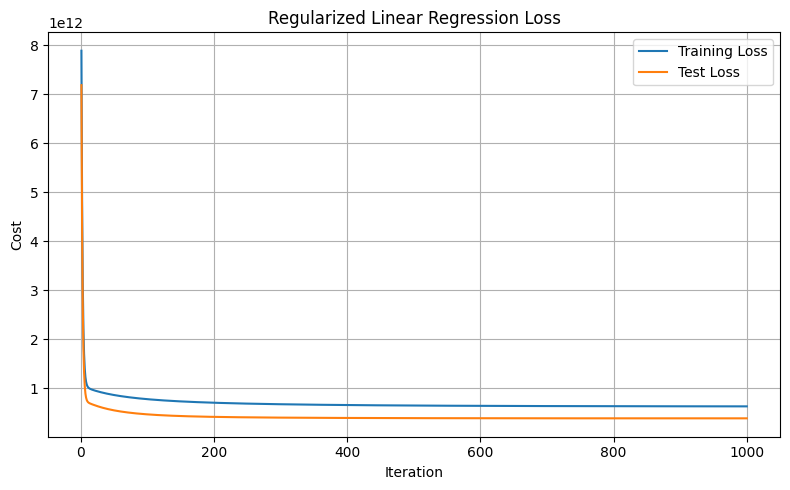

In [ ]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    range(
        1,
        previous_iterations + 1
    ),
    previous_train_cost,
    label='Training Loss'
)

plt.plot(
    range(
        1,
        previous_iterations + 1
    ),
    previous_test_cost,
    label='Test Loss'
)

plt.xlabel(
    'Iteration'
)

plt.ylabel(
    'Cost'
)

plt.title(
    'Regularized Linear Regression Loss'
)

plt.legend()

plt.grid(
    True
)

plt.tight_layout()

plt.show()

### SVR vs Regularized Linear Regression

In [ ]:
regression_comparison = []

for kernel_name in (
    svr_results_df.index
):

    regression_comparison.append({

        'Model':
            'SVR '
            + kernel_name,

        'RMSE':
            svr_results_df.loc[
                kernel_name,
                'Test RMSE'
            ],

        'MAE':
            svr_results_df.loc[
                kernel_name,
                'Test MAE'
            ],

        'R2':
            svr_results_df.loc[
                kernel_name,
                'Test R2'
            ]
    })


regression_comparison.append({

    'Model':
        'Regularized Linear Regression',

    'RMSE':
        previous_rmse,

    'MAE':
        previous_mae,

    'R2':
        previous_r2
})


regression_comparison_df = (
    pd.DataFrame(
        regression_comparison
    )
    .set_index(
        'Model'
    )
)

regression_comparison_df.round(4)

,RMSE,MAE,R2
Model,,,
SVR Linear,868581.3262,652532.4883,0.7540
SVR RBF,857726.2368,659266.2140,0.7601
SVR Polynomial,865513.1841,649926.4501,0.7557
SVR Sigmoid,866018.3918,650236.3806,0.7554
Regularized Linear Regression,873050.7773,663554.3867,0.7514


#### RMSE Model Comparison

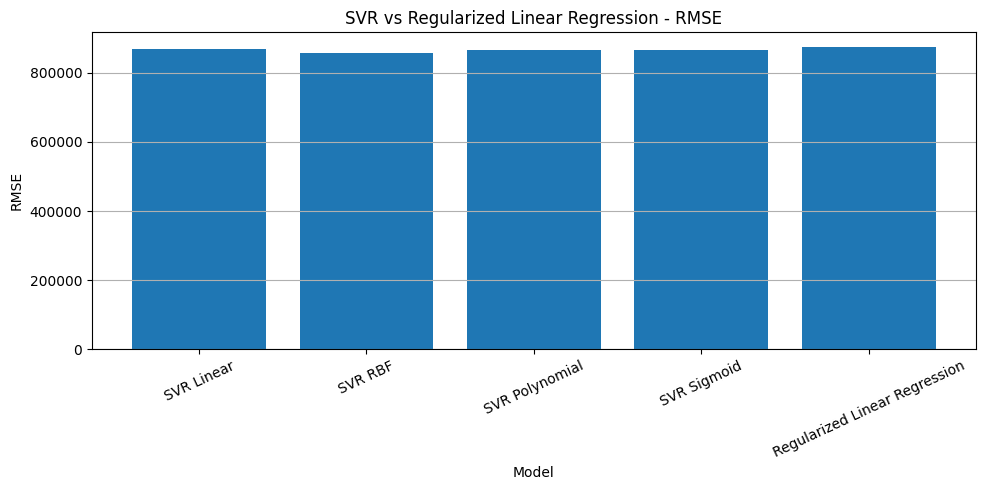

In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.bar(
    regression_comparison_df.index,
    regression_comparison_df[
        'RMSE'
    ]
)

plt.xlabel(
    'Model'
)

plt.ylabel(
    'RMSE'
)

plt.title(
    'SVR vs Regularized Linear Regression - RMSE'
)

plt.xticks(
    rotation=25
)

plt.grid(
    True,
    axis='y'
)

plt.tight_layout()

plt.show()

### R² Model Comparison

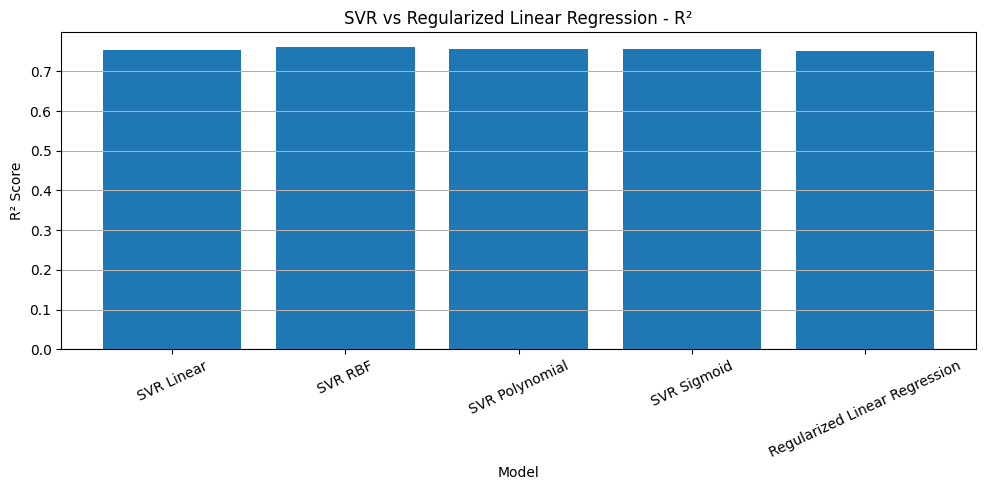

In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.bar(
    regression_comparison_df.index,
    regression_comparison_df[
        'R2'
    ]
)

plt.xlabel(
    'Model'
)

plt.ylabel(
    'R² Score'
)

plt.title(
    'SVR vs Regularized Linear Regression - R²'
)

plt.xticks(
    rotation=25
)

plt.grid(
    True,
    axis='y'
)

plt.tight_layout()

plt.show()

### Select Best SVR Kernel

In [ ]:
best_svr_kernel = max(
    svr_searches,
    key=lambda name:
        svr_searches[
            name
        ].best_score_
)

best_svr_row = (
    svr_results_df.loc[
        best_svr_kernel
    ]
)

print(
    "Best SVR Kernel:",
    best_svr_kernel
)

print(
    "Best SVR Test RMSE:",
    round(
        best_svr_row[
            'Test RMSE'
        ],
        4
    )
)

print(
    "Best SVR Test MAE:",
    round(
        best_svr_row[
            'Test MAE'
        ],
        4
    )
)

print(
    "Best SVR Test R²:",
    round(
        best_svr_row[
            'Test R2'
        ],
        4
    )
)

Best SVR Kernel: Polynomial
Best SVR Test RMSE: 865513.1841
Best SVR Test MAE: 649926.4501
Best SVR Test R²: 0.7557
